# 03 · Parque de vehículos y condiciones de consumo

Para calcular el consumo no basta conocer cuántos coches llegan: también se necesita representar sus tecnologías, tamaños y características físicas. Aquí explico la **selección técnica de vehículos fijada para este estudio**, su procedencia y sus límites. Mantengo las mismas **2.500.000 visitas-persona de 2028** y las condiciones del Excel.

**Qué recibe:** el registro de ejecución y los cuatro archivos de representación técnica identificados. **Qué produce:** si se elige registrar, una copia verificada de esos archivos en la etapa 03 y su procedencia. **Qué comprueba:** identidad, cantidades, cobertura y conservación de la selección. No genera una selección nueva desde los datos brutos, no pondera consumo ni ejecuta COPERT, el programa que proporciona factores de los vehículos.

El registro de esta selección se realiza mediante [etapas_registradas.py](../src/movilidad_teide/flujos/etapas_registradas.py). En 05 se obtienen y comprueban los factores; en 06 se aplican a la actividad y se recalculan sus ponderaciones y las masas que requiere el ajuste físico. Así se evita presentar como puramente descriptivo un perfil que ya incorpora consumo.


## 1. Consultar o registrar una selección fijada

La acción inicial `consultar` abre la selección ya registrada. `registrar` copia y sella las entradas técnicas fijadas de esta referencia, en una ejecución que todavía no tenga 03 completada. **Registrar no equivale a recalcular el parque desde los microdatos originales.** No hay una búsqueda automática de otra selección ni una modificación de los pesos elegidos.

Este paso puede abrirse con un núcleo nuevo. Se recomienda leerlo después de 02 para comprender los recorridos, pero numéricamente 03 solo necesita el registro inicial: no exige reconstruir geografía ni factores COPERT. Utilizo la misma ruta de ejecución para que 06 reciba después esta selección junto con los demás productos.


In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

candidatas = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
RAIZ = next((p for p in candidatas if (p / "pyproject.toml").is_file()
             and (p / "config/parametros_modelo.xlsx").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra este cuaderno desde la raíz del proyecto o desde notebooks/.")
sys.path.insert(0, str(RAIZ / "src"))
from movilidad_teide.configuracion.registro import abrir_ejecucion
from movilidad_teide.flujos.etapas_registradas import ejecutar_etapa


In [2]:
ACCION_PARQUE = "consultar"  # Alternativa explícita: "registrar".
RUTA_EJECUCION = Path("data/silver/ejecuciones/referencia_2028_final_20261116")


In [3]:
if ACCION_PARQUE not in {"consultar", "registrar"}:
    raise ValueError('ACCION_PARQUE debe ser "consultar" o "registrar".')
EJECUCION = RAIZ / RUTA_EJECUCION
if not (EJECUCION / "registro_ejecucion.json").is_file():
    raise FileNotFoundError("No existe el registro seleccionado. Inicie 00 e indique aquí esa misma ruta.")
DATOS = abrir_ejecucion(RAIZ, EJECUCION)
if ACCION_PARQUE == "registrar":
    RESULTADO_ETAPA = ejecutar_etapa(RAIZ, EJECUCION, "03", accion="registrar_datos_fijados")
    DATOS = abrir_ejecucion(RAIZ, EJECUCION)
ETAPA = DATOS["estado_etapas"]["etapas"]["03"]
if ETAPA["estado"] != "completada":
    raise ValueError("No hay selección de parque registrada. Elija registrar en 03 para esa ejecución.")
CARPETA_PARQUE = EJECUCION / ETAPA["carpeta"]
PROCEDENCIA = json.loads((CARPETA_PARQUE / "seleccion_fijada.json").read_text())
SELECCION = CARPETA_PARQUE / "seleccion/data/silver/vehiculos/flota_teide"
DIAGNOSTICO = pd.read_csv(SELECCION / "representacion_tecnica/perfiles_elegidos_diagnostico.csv", sep=";", float_precision="round_trip")
MUNICIPIOS = pd.read_csv(SELECCION / "contraste_municipal_2025.csv", sep=";", float_precision="round_trip")
print("Acción realizada:", ACCION_PARQUE)
print("Ejecución:", DATOS["registro"]["identificador"])
print("Carpeta de selección dentro de la ejecución:", ETAPA["carpeta"])
print("Archivos fijados:", ETAPA["resultado"]["archivos_fijados"])
print("Nueva selección desde bruto realizada:", ETAPA["resultado"]["seleccion_nueva"])


Acción realizada: consultar
Ejecución: referencia_2028_paquetes_20261116
Carpeta de selección dentro de la ejecución: resultados/03/8794af6e180a4004b08da5cf5d639df3
Archivos fijados: 4
Nueva selección desde bruto realizada: False


## 2. Separar el parque registrado de la actividad de visitantes

La Dirección General de Tráfico (**DGT**) aporta registros de vehículos; la estadística municipal permite contrastar sus cantidades. Esos datos describen un **stock**, el número de vehículos registrados en un ámbito y fecha. No indican cuántas veces circulan por el Parque ni qué coche usa cada visitante de 2028.

La selección técnica del estudio se conserva en Silver como una decisión identificada. La tabla 1 muestra los archivos que 03 registra y su función. Los originales de referencia se encuentran en `data/bronze/vehiculos/` y las reglas de correspondencia en `config/` y en los metadatos de la selección. Las [atribuciones](../ATRIBUCIONES.md) documentan sus fuentes y condiciones.

**Tabla 1. Entradas técnicas registradas para representar los turismos del estudio del Teide.**

| Archivo dentro de la selección | Función y alcance |
|---|---|
| `contraste_municipal_2025.csv` | Códigos de los 31 municipios y contraste agregado entre fuentes; sus cantidades no se imponen como total de la selección técnica |
| `propuesta_tamanos_turismos_detalle.csv` | Correspondencias de marca, modelo, tamaño y tecnología, conservando casos incompletos |
| `representacion_tecnica/perfiles_elegidos_diagnostico.csv` | Agrupaciones técnicas y conteos seleccionados, con estados de cobertura y referencias condicionadas |
| `representacion_tecnica/factores_elegidos_resumen.csv` | Resumen técnico fijado que requiere el código de ponderación; también contiene columnas de consumo que no se muestran ni se recalculan aquí |

Fuente: registro de 03, `seleccion_fijada.json`. Aquí leo categorías y cantidades de la selección y compruebo su ámbito mediante dos campos del fichero original de microdatos: tipo de vehículo y municipio. Este control cuenta registros; no elige otros perfiles ni modifica la selección. No leo sus columnas de consumo. Los factores que 06 utiliza deben proceder de 05 y las ponderaciones se calculan después. Registrar un archivo complementario no implica haber ejecutado nuevamente COPERT.


## 3. Cuantificar la base de vehículos sin convertirla en visitas

La tabla 2 conserva los tres grupos de servicio de la selección. Su total se concilia con el detalle de tamaños de la misma base técnica. El contraste municipal agregado contiene otro total: se muestra por separado y no se fuerza su igualdad. La selección utilizada procede de los turismos de los microdatos con municipio identificado en Tenerife; no es una redistribución del total municipal agregado. **“Alquiler sin conductor” es un código de servicio del registro**, no una identificación individual de visitantes extranjeros. El grupo particular tampoco equivale por sí solo a residentes que acceden al Parque. Los otros servicios y los registros sin código se mantienen visibles.

La figura 1 representa esas cantidades para comparar su magnitud. Sus porcentajes no se usan como cuota modal ni como reparto de visitantes. La demanda de 01 procede de las fuentes de movilidad y se mantiene separada de este stock.


In [4]:
stock = DIAGNOSTICO.groupby("grupo_servicio", as_index=False, dropna=False)["vehiculos"].sum()
total_stock = float(stock["vehiculos"].sum())
stock["Porcentaje del stock seleccionado (%)"] = stock["vehiculos"] / total_stock * 100
stock = stock.rename(columns={"grupo_servicio": "Servicio registrado", "vehiculos": "Turismos registrados representados"})
detalle = pd.read_csv(SELECCION / "propuesta_tamanos_turismos_detalle.csv", sep=";", usecols=["vehiculos"])
np.testing.assert_allclose(total_stock, detalle["vehiculos"].sum(), rtol=0, atol=1e-8)
municipios_tenerife = set(MUNICIPIOS["TERRITORIO"].astype(int).astype(str))
conteos_microdatos = {"Tenerife identificado": 0, "Otro municipio publicado de la provincia": 0, "Municipio no publicado": 0}
fuente_microdatos = RAIZ / "data/bronze/vehiculos/dgt_microdatos_2025/provincia_38/38.SANTA_CRUZ_DE_TENERIFE.txt"
for bloque in pd.read_csv(fuente_microdatos, sep="|", encoding="cp1252", dtype=str, keep_default_na=False,
                         usecols=["MUNICIPIO", "TIPO_DGT"], chunksize=100000):
    municipios = bloque.loc[bloque["TIPO_DGT"].str.strip().eq("TURISMOS"), "MUNICIPIO"].str.strip()
    conteos_microdatos["Tenerife identificado"] += int(municipios.isin(municipios_tenerife).sum())
    conteos_microdatos["Municipio no publicado"] += int(municipios.eq("").sum())
    conteos_microdatos["Otro municipio publicado de la provincia"] += int((~municipios.isin(municipios_tenerife) & municipios.ne("")).sum())
np.testing.assert_allclose(conteos_microdatos["Tenerife identificado"], total_stock, rtol=0, atol=1e-8)
display(stock.style.set_uuid("parque_stock").hide(axis="index").format(precision=2, decimal=",", thousands=" ")
        .set_caption("Tabla 2. Base de turismos por servicio registrado, Tenerife identificado, referencia 2025. Fuente: perfiles_elegidos_diagnostico y contraste_municipal_2025; denominador 509.459 vehículos. No son visitantes, viajes ni coches diarios del Teide."))
ambito_microdatos = pd.DataFrame([{"Ámbito identificable en el fichero provincial": k, "Turismos": n} for k, n in conteos_microdatos.items()])
display(ambito_microdatos.style.set_uuid("parque_microdatos").hide(axis="index")
        .set_caption("Tabla 2a. Alcance territorial de los turismos en los microdatos DGT de la provincia 38, referencia 2025. Fuente: fichero Bronze original, campos TIPO_DGT y MUNICIPIO; los no localizados no se asignan a Tenerife. Este control no cambia la selección."))
print("Municipios del contraste:", len(MUNICIPIOS))
print("Total conciliado dentro de la selección técnica:", f"{total_stock:,.0f}".replace(",", " "))
ambitos = pd.DataFrame([
    {"Base de referencia": "Selección técnica de microdatos identificados", "Vehículos": total_stock, "Uso aquí": "Cantidad distribuida entre grupos técnicos; conciliada con el detalle de tamaños"},
    {"Base de referencia": "Contraste municipal agregado", "Vehículos": MUNICIPIOS["vehiculos"].sum(), "Uso aquí": "Códigos municipales y referencia de contraste; no sustituye el total anterior"}])
display(ambitos.style.set_uuid("parque_ambitos").hide(axis="index").format({"Vehículos": "{:,.0f}"}, thousands=" ")
        .set_caption("Tabla 2b. Dos bases preparadas del parque de Tenerife que no se igualan automáticamente. Fuentes: selección técnica y contraste_municipal_2025; la diferencia no se interpreta como vehículos eliminados ni se usa para corregir los pesos."))


Servicio registrado,Turismos registrados representados,Porcentaje del stock seleccionado (%)
Alquiler sin conductor (A01),18 906,"3,71"
Otros servicios o sin código,5 925,"1,16"
Particular sin especificar (B00),484 628,"95,13"


Ámbito identificable en el fichero provincial,Turismos
Tenerife identificado,509459
Otro municipio publicado de la provincia,20191
Municipio no publicado,91131


Municipios del contraste: 31
Total conciliado dentro de la selección técnica: 509 459


Base de referencia,Vehículos,Uso aquí
Selección técnica de microdatos identificados,509 459,Cantidad distribuida entre grupos técnicos; conciliada con el detalle de tamaños
Contraste municipal agregado,554 231,Códigos municipales y referencia de contraste; no sustituye el total anterior


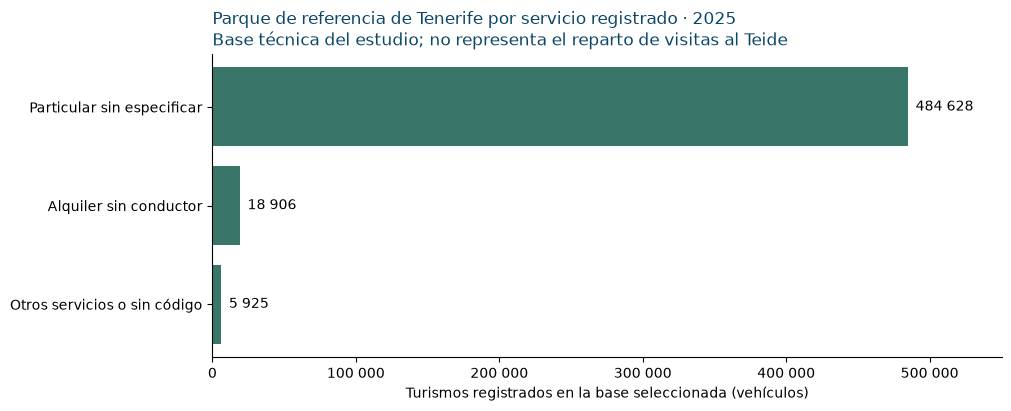

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
orden = stock.sort_values("Turismos registrados representados")
etiquetas = orden["Servicio registrado"].str.replace(" (A01)", "", regex=False).str.replace(" (B00)", "", regex=False)
ax.barh(etiquetas, orden["Turismos registrados representados"], color="#397568")
for posicion, valor in enumerate(orden["Turismos registrados representados"]):
    ax.text(valor, posicion, "  " + f"{valor:,.0f}".replace(",", " "), va="center", fontsize=10)
ax.set_xlim(0, total_stock * 1.08)
ax.set_xlabel("Turismos registrados en la base seleccionada (vehículos)")
ax.set_title("Parque de referencia de Tenerife por servicio registrado · 2025\nBase técnica del estudio; no representa el reparto de visitas al Teide", loc="left", color="#0C4767")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}".replace(",", " ")))
ax.spines[["top", "right"]].set_visible(False)
plt.show()
plt.close(fig)


**Figura 1. Turismos registrados por servicio en la base territorial identificada de Tenerife, referencia 2025.** Fuente: `representacion_tecnica/perfiles_elegidos_diagnostico.csv`, ejecución seleccionada; municipios de Tenerife identificados mediante la lista de 31 códigos. No se iguala su total al contraste agregado municipal. Se muestran 509.459 vehículos, no personas ni circulación anual; la asignación de los visitantes a las referencias de coche se trata por separado.


## 4. Conservar tecnologías, normas y casos incompletos

La **norma Euro** identifica una categoría técnica de emisiones del vehículo; no se deduce simplemente de su edad. La **tecnología de propulsión** distingue los sistemas de gasolina, diésel, híbridos o eléctricos, entre otros. La tabla 3 agrupa las familias técnicas de la selección y mantiene una fila para las no identificadas.

La compatibilidad con un perfil necesita las correspondencias de categoría, tecnología, norma y tamaño declaradas. El detalle de tamaños conserva las reglas de marca y modelo y los casos no identificables. No se asigna otro combustible a un registro solo para completar una curva. **Falta de correspondencia o de factor no significa consumo cero.**

Las referencias condicionadas son elecciones técnicas que permiten representar determinados grupos con cobertura incompleta. Sus marcas y cantidades se conservan en el diagnóstico; su significado no debe confundirse con una medición de consumo ni con cobertura completa de todas las consultas. Las ponderaciones, sustituciones y límites efectivos se explican en 06, utilizando las bibliotecas verificadas de 05.


La política de `.gitignore` determina la disponibilidad documental. Con reserva se comprueban el cálculo, sus referencias obligatorias y las matrices; los documentos reservados se identifican expresamente y no se declara comprobación de sus bytes. Sin reserva se exige también su presencia e integridad.


In [6]:
familias = {"Battery electric": "Eléctrico de batería", "Diesel": "Diésel", "Petrol": "Gasolina",
    "LPG Bifuel": "Bifuel con gas licuado del petróleo", "CNG Bifuel": "Bifuel con gas natural comprimido",
    "Petrol Hybrid": "Híbrido de gasolina", "Petrol PHEV": "Híbrido enchufable de gasolina", "Diesel PHEV": "Híbrido enchufable diésel"}
tecnologias = DIAGNOSTICO.assign(Familia=DIAGNOSTICO["familia_copert"].map(familias).fillna("Sin familia identificada"))
resumen_tecnologias = tecnologias.groupby("Familia", as_index=False)["vehiculos"].sum().rename(columns={"Familia": "Familia técnica", "vehiculos": "Turismos registrados"})
np.testing.assert_allclose(resumen_tecnologias["Turismos registrados"].sum(), total_stock, rtol=0, atol=1e-8)
display(resumen_tecnologias.style.set_uuid("parque_tecnologias").hide(axis="index")
        .set_caption("Tabla 3. Familias técnicas de los turismos de Tenerife identificados, referencia 2025. Fuente: perfiles_elegidos_diagnostico de esta ejecución; incluye los registros sin familia identificada y no expresa consumo ni emisiones."))


Familia técnica,Turismos registrados
Bifuel con gas licuado del petróleo,2531
Bifuel con gas natural comprimido,16
Diésel,95198
Eléctrico de batería,5509
Gasolina,379866
Híbrido de gasolina,20501
Híbrido enchufable de gasolina,4665
Híbrido enchufable diésel,90
Sin familia identificada,1083


## 5. Relacionar las referencias de coche con la procedencia de los visitantes

El reparto de visitantes no se obtiene de los porcentajes de la figura 1. La comparación energética conserva dos asignaciones para el grupo de visitantes de España no Tenerife. La tabla 4 explica esa diferencia; ambas mantienen la misma demanda y operación. El intervalo de resultados que producen no se interpreta como un intervalo estadístico de confianza.

**Tabla 4. Asignaciones de referencia de turismos a los visitantes del estudio de 2028.**

| Procedencia del visitante | Asignación con alquiler para España no Tenerife | Asignación con particular para España no Tenerife |
|---|---|---|
| Extranjero | Referencia de alquiler | Referencia de alquiler |
| Residente de Tenerife | Referencia particular | Referencia particular |
| España no Tenerife | Referencia de alquiler | Referencia particular |

Fuente: criterio del [informe vigente](../docs/informe_energetico/INFORME_ENERGETICO_v0.28_2026-11-16.pdf), [guía del balance](../docs/preparacion_balance.md) y funciones de [energia/referencia.py](../src/movilidad_teide/energia/referencia.py). La asignación es una hipótesis de representación del parque utilizado, no una observación individual. Las dos alternativas se comparan; no se suman como vehículos o visitas adicionales. Los grupos del inventario se conservan con sus cantidades y estados originales.


## 6. Explicitar las velocidades y la carga que se usarán al valorar energía

La tabla 5 lee las condiciones del modelo resueltas desde el Excel. En turismos se distinguen las clases local, convencional y rápida; el autocar tiene su velocidad técnica de referencia. **Estas velocidades sirven para evaluar factores de consumo**, no para prometer un tiempo comercial de cada servicio ni para sustituir sus horarios.

Las consultas públicas de autocares se preparan a 34 km/h; las de turismos contienen distintas velocidades, incluidas condiciones complementarias. La tabla 5 muestra las velocidades que utiliza el balance, sin identificar esa tabla con toda la lista de consultas. 05 explica las combinaciones exactas de velocidad, pendiente y carga y cómo se ejecutan. La carga técnica de 0,5 es una condición de referencia de la curva y no una afirmación de que el autobús lleve exactamente el 50 % de sus plazas ocupadas. Las plazas, las personas transportadas y la ocupación comercial se comprueban en 04.

La referencia de autocar utilizada para lanzaderas, TITSA y excursiones es diésel, autocar estándar de hasta 18 t y norma Euro VI D/E. Es una categoría técnica de factores, no la identificación o certificación de cada autobús real. Se comprueba en el [índice de consultas COPERT](../data/bronze/copert/entradas_publicas/consultas.csv) y en [preparacion_coeficientes.py](../src/movilidad_teide/energia/preparacion_coeficientes.py). Lanzaderas y TITSA utilizan sus perfiles dirigidos de 02. Las excursiones mantienen un factor de pendiente cero en ambos escenarios principales; esta hipótesis común no significa que sus recorridos sean llanos.

La **tara** es la masa del vehículo sin la carga de ocupantes considerada en el ajuste. La masa por ocupante y su ocupación figuran por separado. En 06 se obtienen las masas por grupo desde los microdatos DGT y se aplica la corrección física de pendiente de los turismos; registrar la selección aquí no equivale a haberlas recalculado.


In [7]:
v = DATOS["configuracion"]["valores_modelo"]
condiciones = pd.DataFrame([
    {"Condición posterior del modelo": "Turismo en vía local", "Valor": v["velocidad_turismo_local"], "Unidad": "km/h", "Función": "Velocidad de evaluación del consumo"},
    {"Condición posterior del modelo": "Turismo en vía convencional", "Valor": v["velocidad_turismo_convencional"], "Unidad": "km/h", "Función": "Velocidad de evaluación del consumo"},
    {"Condición posterior del modelo": "Turismo en vía rápida", "Valor": v["velocidad_turismo_rapida"], "Unidad": "km/h", "Función": "Velocidad de evaluación del consumo"},
    {"Condición posterior del modelo": "Autocar de referencia", "Valor": v["velocidad_copert"], "Unidad": "km/h", "Función": "Velocidad de evaluación del consumo"},
    {"Condición posterior del modelo": "Carga técnica de referencia", "Valor": v["carga_copert"], "Unidad": "fracción", "Función": "Condición de curva; no porcentaje de plazas ocupadas"},
    {"Condición posterior del modelo": "Ocupación del coche", "Valor": v["ocupacion_coche"], "Unidad": "personas/coche", "Función": "Conversión entre personas y vehículos según el reparto"},
    {"Condición posterior del modelo": "Masa por ocupante del turismo", "Valor": v["masa_persona_turismo_kg"], "Unidad": "kg/persona", "Función": "Entrada del ajuste físico de pendiente de turismos"}])
display(condiciones.style.set_uuid("parque_condiciones").hide(axis="index").format(precision=2, decimal=",", thousands=" ")
        .set_caption("Tabla 5. Condiciones de consumo y carga de la referencia del Teide para 2028. Fuente: valores_modelo de la configuración comprobada con el Excel. Aquí se presentan entradas; no se calcula energía ni se identifica carga técnica con ocupación comercial."))


Condición posterior del modelo,Valor,Unidad,Función
Turismo en vía local,"20,00",km/h,Velocidad de evaluación del consumo
Turismo en vía convencional,"40,00",km/h,Velocidad de evaluación del consumo
Turismo en vía rápida,"80,00",km/h,Velocidad de evaluación del consumo
Autocar de referencia,"34,00",km/h,Velocidad de evaluación del consumo
Carga técnica de referencia,"0,50",fracción,Condición de curva; no porcentaje de plazas ocupadas
Ocupación del coche,"3,20",personas/coche,Conversión entre personas y vehículos según el reparto
Masa por ocupante del turismo,"75,00",kg/persona,Entrada del ajuste físico de pendiente de turismos


## 7. Comprobar la identidad de las entradas registradas

La tabla 6 muestra la procedencia y la huella SHA-256 de los cuatro archivos copiados. Una huella identifica los bytes y detecta cambios; no demuestra por sí sola representatividad del parque ni aprobación institucional. La apertura verifica también las huellas de sus productos. No se modifica el original de Silver ni se busca otra versión de forma automática.

Las cantidades se concilian entre el diagnóstico seleccionado y el detalle de tamaños de la misma base. El contraste municipal se conserva como otra referencia. Los microdatos provinciales incluyen turismos sin municipio publicado: no se asignan a Tenerife ni se presume que expliquen por sí solos la diferencia con el agregado municipal. La conciliación entre ambas fuentes debe quedar revisada antes de adoptar la edición final. No se presupone su causa ni se corrigen los pesos para hacerla desaparecer. Los casos incompletos permanecen en las tablas, de modo que la etapa de factores y el balance puedan tratarlos con los criterios declarados. La equivalencia del registro se comprueba archivo a archivo; no se presenta como una nueva clasificación completa desde los microdatos.


In [8]:
inventario = pd.DataFrame(PROCEDENCIA["archivos"])[["origen", "sha256"]].rename(columns={"origen": "Entrada técnica identificada", "sha256": "Huella SHA-256 del archivo"})
display(inventario.style.set_uuid("parque_archivos").hide(axis="index")
        .set_properties(**{"white-space": "normal", "max-width": "40em"})
        .set_caption("Tabla 6. Procedencia de las cuatro entradas fijadas para el parque del estudio del Teide. Fuente: seleccion_fijada.json de esta ejecución; las copias registradas conservan sus bytes y no son una selección nueva desde bruto."))


Entrada técnica identificada,Huella SHA-256 del archivo
data/silver/vehiculos/flota_teide/contraste_municipal_2025.csv,edc6ec957da9d879dcd85a951a9836c9147e4a4ebe1243f43f955f6147210c61
data/silver/vehiculos/flota_teide/propuesta_tamanos_turismos_detalle.csv,4038aea0a3e7fc85f4e0c04884cab1bbdded1255faa507b9ad2820833a8df650
data/silver/vehiculos/flota_teide/representacion_tecnica/factores_elegidos_resumen.csv,eaca1047ef1bce6fd4f8020e8b7e7d4e0e5451a9041ae45e79e65cc918352da8
data/silver/vehiculos/flota_teide/representacion_tecnica/perfiles_elegidos_diagnostico.csv,89e818e09f089b38b6d1f6f3998b1ae3562b096c6b81a8b80c6a8057803f58c0


## 8. Límites y continuación del recorrido

El parque registrado de 2025 es una referencia para representar vehículos de visitantes de 2028. Su uso requiere las hipótesis explícitas de procedencia, tecnología y tamaño; las cantidades registrales no demuestran kilometraje anual, ocupación, consumo observado ni la composición exacta de las llegadas al Parque. Se mantienen los registros incompletos y sus límites, sin reinterpretarlos como cantidades nulas.

La siguiente etapa es [04 · Servicio y actividad](04_servicio_y_actividad.ipynb): comprueba cómo transportar la demanda con cupos, plazas, unidades, tiempos e idas y regresos. Elijo `consultar` o, tras completar01y02en esta ejecución, `comprobar`. Los comandos equivalentes están en la [guía de etapas](../docs/ejecucion_por_etapas.md) con esta misma ruta. 05 obtendrá los factores identificados y 06 calculará ponderaciones, consumo, ahorro y sensibilidades. No se ejecutan esos pasos al abrir 03.

El [mapa del recorrido](../docs/recorrido_notebooks.md) sitúa cada materia y sus dependencias. Las hipótesis siguen editándose en el Excel, las fórmulas en el código compartido y los resultados nuevos en Silver. El informe, sus anexos y los datos de referencia permanecen intactos.
